# Bearing degradation with tseriz — analysis (v2)
One healthy baseline and two degradation series, all generated with **the same seed (4242)**, 8192 Hz, 20 s. The first 10 s are healthy in all three; degradation starts at t = 10 s and runs to 20 s.

| Series | What changes from 10 s to 20 s |
|---|---|
| **Baseline** | nothing |
| **Case A — naive** | pink noise ×1.5 and white noise ×9 (statistical "it gets noisier") |
| **Case B — physics** | impacts at the inner-race rate (162 Hz) ringing a 600 Hz resonance, amplitude ×5; pink noise ×1.5 |

White-noise gain in Case A was chosen so that the RMS growth of A and B is the same. Everything below uses the **sample index** as time axis (the CSV timestamp step is 2.6 ppm slow).

**Data needed to run this notebook.** It analyses full-length series (163,841 points each), which are not stored in git:
- `data/full/baseline.csv`, `case_a.csv`, `case_b.csv` (seed 4242): run `python tools/generate_batch.py --reference-set`, or generate them in the tseriz UI from `configs/*.json` and download the CSVs under these names.
- Section 4 uses 90 series in `data/full/mc/` (`python tools/generate_batch.py`). If `results/mc_features.csv` exists it is used instead, so section 4 also runs without them.
- Short samples that fit the free tier are in `data/samples/`; use `notebooks/quickstart_samples.ipynb` for those.


In [1]:
import os, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# Paths are relative to the repository root (the notebook may be started from the root or from notebooks/).
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = Path(os.environ.get("TSERIZ_DATA", ROOT / "data" / "full"))        # full-length series (not in git; see README)
CONFIGS = Path(os.environ.get("TSERIZ_CONFIGS", ROOT / "configs"))        # the four tseriz configs
FIG = Path(os.environ.get("TSERIZ_FIG", ROOT / "figures"));  FIG.mkdir(exist_ok=True, parents=True)
RESULTS = Path(os.environ.get("TSERIZ_RESULTS", ROOT / "results")); RESULTS.mkdir(exist_ok=True, parents=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 10})

In [2]:
# --- analysis helpers (self-contained; numpy / scipy / pandas) ---
import json, numpy as np, pandas as pd
from scipy.signal import butter, sosfiltfilt, hilbert, welch, lfilter

FS = 8192; ONSET = 10.0; END = 20.0; BPFI = 162.0; F_RES = 600.0; ZETA = 0.1
BAND = (400, 800)      # resonance band for the envelope
FILES = {"Baseline": "baseline.csv", "Case A (naive)": "case_a.csv", "Case B (physics)": "case_b.csv"}
CFG = {"Baseline": "baseline.json", "Case A (naive)": "case_a.json", "Case B (physics)": "case_b.json"}
COLORS = {"Baseline": "#6b7280", "Case A (naive)": "#d97706", "Case B (physics)": "#2563eb"}

def load(folder):
    out = {}
    for k, f in FILES.items():
        x = pd.read_csv(f"{folder}/{f}")["vibration"].to_numpy(float); out[k] = x
    t = np.arange(len(x)) / FS
    return t, out

def load_cfg(folder):
    return {k: json.load(open(f"{folder}/{f}")) for k, f in CFG.items()}

def band_env(x, band=BAND, fs=FS):
    sos = butter(4, band, "bp", fs=fs, output="sos"); y = sosfiltfilt(sos, x); return y, np.abs(hilbert(y))

def fit_lines(x, t, freqs=(30, 60, 90)):
    """Least-squares fit of sine+cosine at each shaft harmonic; returns fitted signal and (amp, phase) list."""
    A = np.column_stack([f(2 * np.pi * fr * t) for fr in freqs for f in (np.sin, np.cos)])
    c, *_ = np.linalg.lstsq(A, x, rcond=None); return A @ c, [(np.hypot(c[2*i], c[2*i+1])) for i in range(len(freqs))]

def env_line(x, fs=FS, f0=BPFI, bw=1.5, bg=(5, 40)):
    """Envelope-spectrum line-to-background ratio at f0 for a segment x (band 400-800 Hz envelope)."""
    _, e = band_env(x); e = e - e.mean(); n = len(e)
    F = np.abs(np.fft.rfft(e * np.hanning(n))); fr = np.fft.rfftfreq(n, 1 / fs)
    k = np.abs(fr - f0) < bw; b = (np.abs(fr - f0) > bg[0]) & (np.abs(fr - f0) < bg[1])
    return F[k].max() / np.median(F[b])

def envelope_spectrum(x, fs=FS):
    _, e = band_env(x); e = e - e.mean(); n = len(e)
    F = 2 * np.abs(np.fft.rfft(e * np.hanning(n))) / np.sum(np.hanning(n)); return np.fft.rfftfreq(n, 1 / fs), F

def kurt(v):
    v = v - v.mean(); return np.mean(v ** 4) / np.mean(v ** 2) ** 2

def window_features(x, t, win=1.0, step=0.25, fs=FS):
    """Sliding-window features. Band signals are computed once on the whole record (zero-phase filter)."""
    yb, _ = band_env(x); n = int(win * fs); s = int(step * fs); rows = []
    for i in range(0, len(x) - n + 1, s):
        seg = x[i:i + n]; sb = yb[i:i + n]
        rows.append(dict(t=t[i] + win / 2, rms=seg.std(), band_rms=sb.std(), kurt_band=kurt(sb),
                         crest_band=np.max(np.abs(sb)) / sb.std(), bpfi_line=env_line(seg)))
    return pd.DataFrame(rows)

def alarm_time(tt, v, thr, k=3):
    """First time at which v exceeds thr in k consecutive windows (time of the k-th)."""
    run = 0
    for ti, vi in zip(tt, v):
        run = run + 1 if vi > thr else 0
        if run >= k: return ti
    return np.nan

def unit_response(tau, wn=2 * np.pi * F_RES, z=ZETA):
    a = z * wn; wd = wn * np.sqrt(1 - z * z); tp = np.arctan2(wd, a) / wd
    return np.exp(-a * tau) * np.sin(wd * tau) / (np.exp(-a * tp) * np.sin(wd * tp))

def train_regressors(n, fs=FS, onset=ONSET, end=END, rate=BPFI):
    """Two regressors: unit train and (t-onset) weighted train, filtered by the sampled resonance response."""
    on = onset + np.arange(int(np.floor((end - onset) * rate + 1e-9)) + 1) / rate
    idx = np.rint(on * fs).astype(int); idx = idx[idx < n]
    wn = 2 * np.pi * F_RES; a = ZETA * wn; dt = 1 / fs
    h1 = float(unit_response(np.array([dt]))[0]); p = 2 * np.exp(-a * dt) * np.cos(wn * np.sqrt(1 - ZETA ** 2) * dt); q = np.exp(-2 * a * dt)
    out = []
    for w in (np.ones(len(idx)), on[:len(idx)] - onset):
        x = np.zeros(n); np.add.at(x, idx, w); out.append(lfilter([0, h1], [1, -p, q], x))
    return np.column_stack(out), on

def fit_fault_train(x, t):
    """Joint least squares: shaft lines + fault train with amplitude a0 + a1*(t-onset). Returns a0, a1 and standard errors."""
    lines = np.column_stack([f(2 * np.pi * fr * t) for fr in (30, 60, 90) for f in (np.sin, np.cos)])
    R, _ = train_regressors(len(x)); A = np.column_stack([lines, R])
    c, *_ = np.linalg.lstsq(A, x, rcond=None); r = x - A @ c
    cov = np.linalg.inv(A.T @ A) * r.var(ddof=A.shape[1]); se = np.sqrt(np.diag(cov))
    return c[-2], c[-1], se[-2], se[-1]

## 1. Do the data match the configuration?
Before interpreting anything, check that what tseriz produced is what the config says. Three checks that need no assumptions about the analysis method.

In [3]:
t, X = load(DATA); cfgs = load_cfg(CONFIGS); names = list(X); base = X["Baseline"]
pre = t < ONSET
checks = []
# (a) shaft lines: least-squares amplitude vs config
for k, x in X.items():
    _, amps = fit_lines(x[pre], t[pre])
    checks.append((k, "shaft 30/60/90 Hz amplitude [g]", " / ".join(f"{a:.3f}" for a in amps), "0.500 / 0.200 / 0.100"))
# (b) same seed => healthy segments are bit-identical across series
for k in names[1:]:
    checks.append((k, "max |x - baseline|, t < 10 s", f"{np.abs(X[k][pre] - base[pre]).max():.1e}", "0 (same seed)"))
# (c) fault train: joint least squares recovers the configured amplitude law a(t) = a0 + a1 (t - 10)
for k in names:
    a0, a1, s0, s1 = fit_fault_train(X[k], t)
    checks.append((k, "fitted impact amplitude a0 [g], slope a1 [g/s]", f"{a0:+.4f} +/- {s0:.4f},  {a1:+.4f} +/- {s1:.4f}", "0.100, 0.040 (case B) / 0, 0 otherwise"))
val = pd.DataFrame(checks, columns=["series", "check", "measured", "configured"]); val

,series,check,measured,configured
0,Baseline,shaft 30/60/90 Hz amplitude [g],0.500 / 0.201 / 0.100,0.500 / 0.200 / 0.100
1,Case A (naive),shaft 30/60/90 Hz amplitude [g],0.500 / 0.201 / 0.100,0.500 / 0.200 / 0.100
2,Case B (physics),shaft 30/60/90 Hz amplitude [g],0.500 / 0.201 / 0.100,0.500 / 0.200 / 0.100
3,Case A (naive),"max |x - baseline|, t < 10 s",0.0e+00,0 (same seed)
4,Case B (physics),"max |x - baseline|, t < 10 s",0.0e+00,0 (same seed)
5,Baseline,"fitted impact amplitude a0 [g], slope a1 [g/s]","+0.0020 +/- 0.0010, -0.0007 +/- 0.0002","0.100, 0.040 (case B) / 0, 0 otherwise"
6,Case A (naive),"fitted impact amplitude a0 [g], slope a1 [g/s]","+0.0004 +/- 0.0019, -0.0004 +/- 0.0003","0.100, 0.040 (case B) / 0, 0 otherwise"
7,Case B (physics),"fitted impact amplitude a0 [g], slope a1 [g/s]","+0.1020 +/- 0.0012, +0.0391 +/- 0.0002","0.100, 0.040 (case B) / 0, 0 otherwise"


In [4]:
# (d) pink-noise ramp: same seed => (series - baseline) = (scale(t) - 1) * pink(t) (+ fault / white). Regress it on the baseline's low band.
from scipy.signal import butter, sosfiltfilt
br = base - fit_lines(base, t)[0]                       # remove shaft lines first (30 Hz leaks into a 3-25 Hz band otherwise)
sos = butter(4, [3, 20], "bp", fs=FS, output="sos"); lb = sosfiltfilt(sos, br)
rows = []
for s in range(10, 20):
    m = (t >= s) & (t < s + 1); r = {"window [s]": f"{s}-{s+1}", "configured scale-1": round(0.05 * (s + .5 - 10), 3)}
    for k in names[1:]:
        ld = sosfiltfilt(sos, X[k] - base); r[k] = round((lb[m] @ ld[m]) / (lb[m] @ lb[m]), 3)
    rows.append(r)
pink = pd.DataFrame(rows); pink

,window [s],configured scale-1,Case A (naive),Case B (physics)
0,10-11,0.025,0.030,0.027
1,11-12,0.075,0.087,0.078
2,12-13,0.125,0.111,0.134
3,13-14,0.175,0.222,0.174
4,14-15,0.225,0.173,0.235
5,15-16,0.275,0.312,0.277
6,16-17,0.325,0.291,0.330
7,17-18,0.375,0.420,0.369
8,18-19,0.425,0.547,0.423
9,19-20,0.475,0.472,0.475


**Reading the checks.** The shaft lines match the config to within 0.2 %. The healthy 10 s are *bit-identical* in the three series, so any difference after 10 s is caused by the degradation and nothing else — this is the paired design that real measurements can never give you. The impact train is recovered by least squares with the configured amplitude law (a₀ = 0.1 g, slope 0.04 g/s), and the "+50 % pink noise" claim is verified: the pink-noise scale grows linearly from 1 to 1.5, window by window (Case B column), as configured.

## 2. What does the degradation look like?

### The raw data around the onset
Before any analysis, here is what tseriz actually returned. Each series is a two-column CSV (`timestamp`, `vibration`) with 163,841 rows. The table shows the rows around the onset at 10 s for the baseline, Case A and Case B (seed 4242). Up to and including the row at 10 s the three values are identical, because the series share a seed and a configuration. From the next row the series separate: Case B starts ringing from its first impact at 10 s, while Case A has only just begun its noise ramp and differs from the baseline in the sixth decimal. The lower panels show the difference from the baseline, which is the degradation on its own: at the onset (left) and 10 s later, at the end of the record (right).

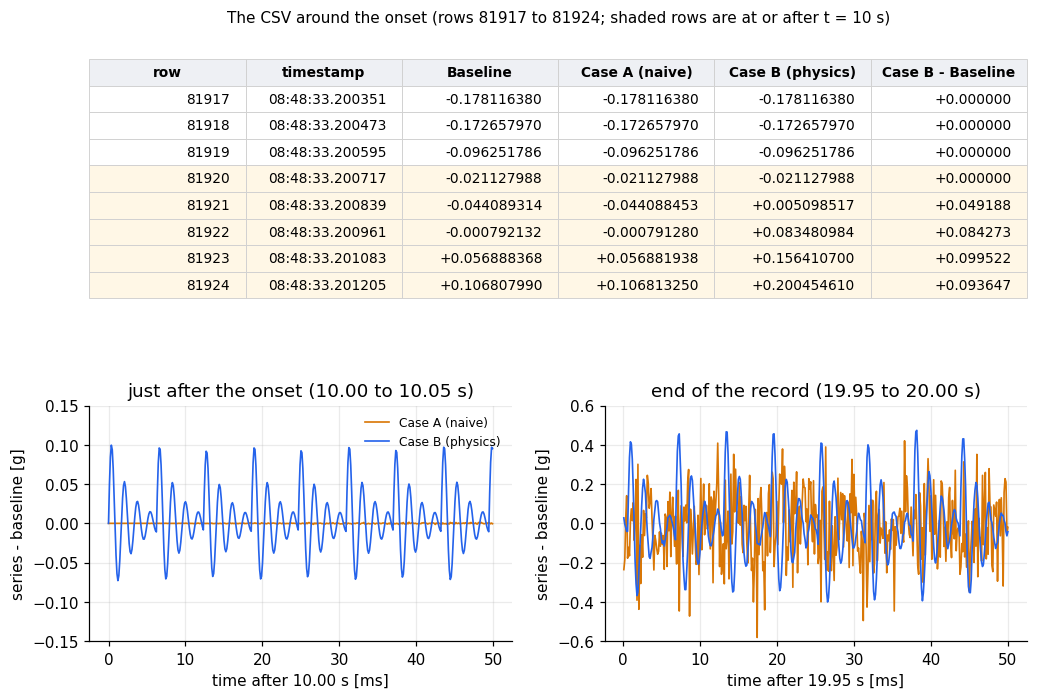

In [5]:
import matplotlib.gridspec as gridspec
raw = pd.read_csv(DATA / FILES["Baseline"], dtype={"timestamp": str})            # raw timestamp text, as tseriz wrote it
i0 = int(round(ONSET * FS)); rows = range(i0 - 3, i0 + 5)
tab = [[f"{i}", raw.timestamp.iloc[i][11:26], f"{X['Baseline'][i]:+.9f}", f"{X['Case A (naive)'][i]:+.9f}", f"{X['Case B (physics)'][i]:+.9f}", f"{X['Case B (physics)'][i] - X['Baseline'][i]:+.6f}"] for i in rows]
fig = plt.figure(figsize=(11, 7.2)); gs = gridspec.GridSpec(2, 2, height_ratios=[1.25, 1], hspace=.3, wspace=.22)
at = fig.add_subplot(gs[0, :]); at.axis("off")
tb = at.table(cellText=tab, colLabels=["row", "timestamp", "Baseline", "Case A (naive)", "Case B (physics)", "Case B - Baseline"], loc="center", cellLoc="right")
tb.auto_set_font_size(False); tb.set_fontsize(9); tb.scale(1, 1.45)
for (r, c), cell in tb.get_celld().items():
    cell.set_edgecolor("#d0d0d0"); cell.set_linewidth(.6)
    if r == 0: cell.set_facecolor("#eef0f4"); cell.set_text_props(weight="bold")
    elif rows[r - 1] >= i0: cell.set_facecolor("#fff7e6")
at.set_title(f"The CSV around the onset (rows {i0-3} to {i0+4}; shaded rows are at or after t = 10 s)", fontsize=10)
for j, (a, b, ttl) in enumerate([(ONSET, ONSET + .05, "just after the onset (10.00 to 10.05 s)"), (END - .05, END, "end of the record (19.95 to 20.00 s)")]):
    ax_ = fig.add_subplot(gs[1, j]); m = (t >= a) & (t <= b)
    for k in names[1:]: ax_.plot((t[m] - a) * 1e3, (X[k] - base)[m], color=COLORS[k], lw=1.1, label=k)
    ax_.set(xlabel=f"time after {a:.2f} s [ms]", ylabel="series - baseline [g]", title=ttl, ylim=((-.15, .15) if j == 0 else (-.6, .6)))
    if j == 0: ax_.legend(frameon=False, fontsize=8, loc="upper right")
fig.savefig(FIG / "09_raw_data_snippet.png", bbox_inches="tight"); plt.show()

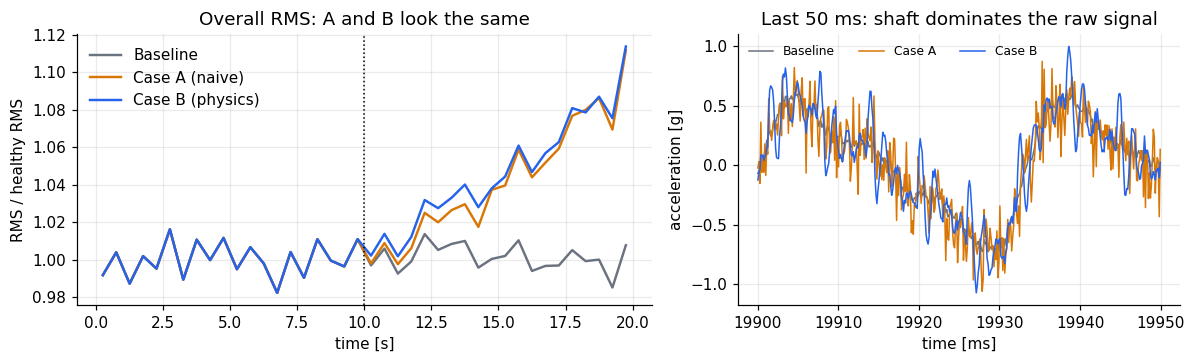

{'Baseline': -0.0030913231875374647,
 'Case A (naive)': 0.08613029435600494,
 'Case B (physics)': 0.08787297648740666}

In [6]:
def rolling_rms(x, win=0.5):
    n = int(win * FS); k = len(x) // n; return (np.arange(k) + .5) * win, np.sqrt((x[:k*n].reshape(k, n) ** 2).mean(1) - x[:k*n].reshape(k, n).mean(1) ** 2)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.3, 1]})
for k in names:
    tr_, r_ = rolling_rms(X[k]); ax[0].plot(tr_, r_ / r_[tr_ < 10].mean(), label=k, color=COLORS[k], lw=1.6)
ax[0].axvline(ONSET, color="k", ls=":", lw=1); ax[0].set(xlabel="time [s]", ylabel="RMS / healthy RMS", title="Overall RMS: A and B look the same"); ax[0].legend(frameon=False)
w = (t >= 19.90) & (t < 19.95)
ax[1].plot(t[w] * 1e3, base[w], color=COLORS["Baseline"], lw=1, label="Baseline"); ax[1].plot(t[w] * 1e3, X["Case A (naive)"][w], color=COLORS["Case A (naive)"], lw=1, label="Case A"); ax[1].plot(t[w] * 1e3, X["Case B (physics)"][w], color=COLORS["Case B (physics)"], lw=1, label="Case B")
ax[1].set(xlabel="time [ms]", ylabel="acceleration [g]", title="Last 50 ms: shaft dominates the raw signal"); ax[1].legend(frameon=False, ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "01_rms_and_raw.png", bbox_inches="tight"); plt.show()
rms_growth = {k: float(X[k][t >= 18].std() / X[k][t < 10].std() - 1) for k in names}; rms_growth

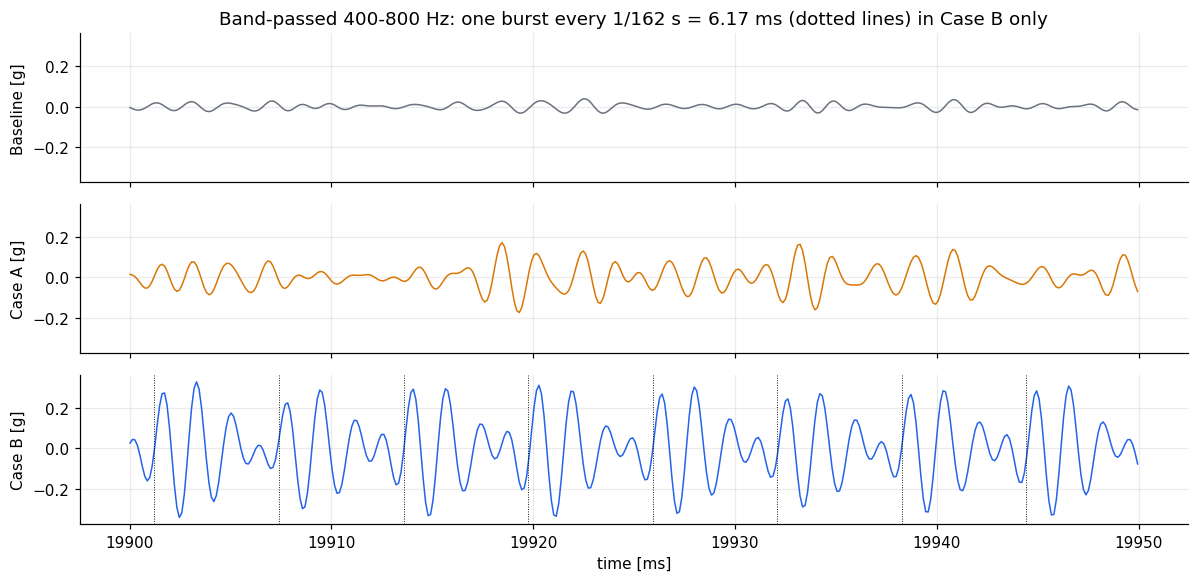

In [7]:
# Resonance-band view (400-800 Hz): the impacts become visible once the shaft is filtered out
fig, ax = plt.subplots(3, 1, figsize=(11, 5.4), sharex=True, sharey=True)
w = (t >= 19.90) & (t < 19.95)
for a, k in zip(ax, names):
    yb, _ = band_env(X[k]); a.plot(t[w] * 1e3, yb[w], color=COLORS[k], lw=1); a.set_ylabel(k.split(" (")[0] + " [g]")
on = ONSET + np.arange(int((END - ONSET) * BPFI) + 1) / BPFI
for o in on[(on >= 19.90) & (on < 19.95)]: ax[2].axvline(o * 1e3, color="k", lw=.6, ls=":")
ax[0].set_title("Band-passed 400-800 Hz: one burst every 1/162 s = 6.17 ms (dotted lines) in Case B only"); ax[2].set_xlabel("time [ms]")
fig.tight_layout(); fig.savefig(FIG / "02_resonance_band_zoom.png", bbox_inches="tight"); plt.show()

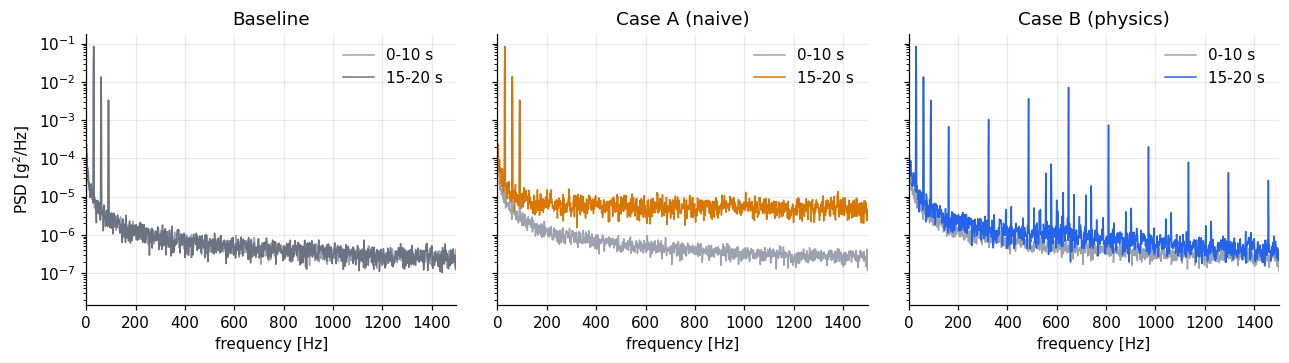

In [8]:
# Spectra: healthy (0-10 s) vs late degradation (15-20 s)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, k in zip(ax, names):
    for seg, ls_, lab in (((0, 10), "-", "0-10 s"), ((15, 20), "-", "15-20 s")):
        m = (t >= seg[0]) & (t < seg[1]); f, P = welch(X[k][m], FS, nperseg=8192, window="hann")
        a.semilogy(f, P, ls_, color=COLORS[k] if seg[0] else "#9ca3af", lw=1, label=lab)
    a.set(xlim=(0, 1500), title=k, xlabel="frequency [Hz]"); a.legend(frameon=False)
ax[0].set_ylabel("PSD [g$^2$/Hz]"); fig.tight_layout(); fig.savefig(FIG / "03_spectra.png", bbox_inches="tight"); plt.show()

A's late spectrum is lifted across the whole band (white noise ×9). B's fault is a comb at multiples of 162 Hz riding on a 600 Hz resonance hump — much smaller in energy, which is why RMS barely sees it. The envelope spectrum is the tool that makes it obvious.

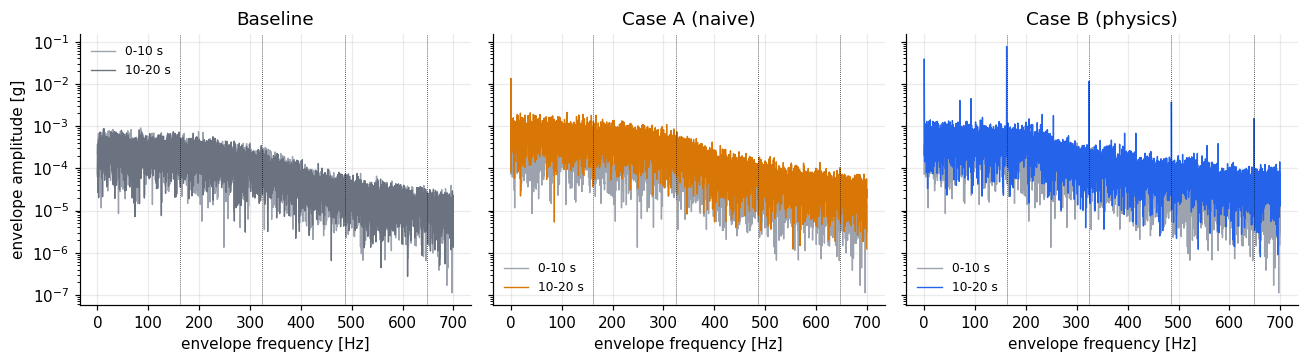

,1x,2x,3x
Baseline,2.7,2.6,2.7
Case A (naive),2.3,2.3,1.8
Case B (physics),172.8,73.9,48.9


In [9]:
# Envelope spectrum of the 400-800 Hz band, fault window 10-20 s vs healthy 0-10 s
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for a, k in zip(ax, names):
    for seg, c in (((0, 10), "#9ca3af"), ((10, 20), COLORS[k])):
        m = (t >= seg[0]) & (t < seg[1]); f, E = envelope_spectrum(X[k][m]); sel = f < 700; a.semilogy(f[sel], E[sel] + 1e-12, color=c, lw=.9, label=f"{seg[0]}-{seg[1]} s")
    for h in (1, 2, 3, 4): a.axvline(h * BPFI, color="k", lw=.5, ls=":")
    a.set(title=k, xlabel="envelope frequency [Hz]"); a.legend(frameon=False, fontsize=8)
ax[0].set_ylabel("envelope amplitude [g]"); fig.tight_layout(); fig.savefig(FIG / "04_envelope_spectrum.png", bbox_inches="tight"); plt.show()
env_lines = {k: {f"{h}x": float(env_line(X[k][(t >= 10)], f0=h * BPFI)) for h in (1, 2, 3)} for k in names}; pd.DataFrame(env_lines).T.round(1)

## 3. Detection: which indicator sees the fault first, and which can tell A from B?

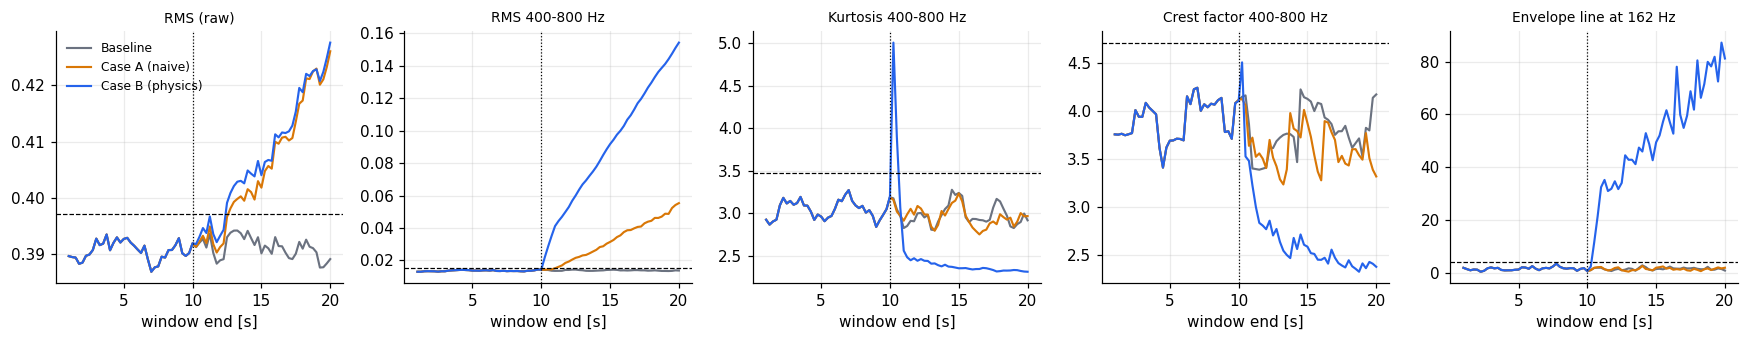

,indicator,threshold (healthy mean + 4 sd),Case A (naive),Case B (physics),false alarms in healthy 0-10 s
0,RMS (raw),0.3973,3.25 s,3.00 s,0
1,RMS 400-800 Hz,0.0150,1.50 s,0.75 s,0
2,Kurtosis 400-800 Hz,3.4772,no alarm,no alarm,0
3,Crest factor 400-800 Hz,4.7115,no alarm,no alarm,0
4,Envelope line at 162 Hz,3.9173,no alarm,1.00 s,0


In [10]:
F = {k: window_features(X[k], t, win=1.0, step=0.25) for k in names}
for d in F.values(): d["t_end"] = d.t + 0.5          # causal: a window can only raise an alarm once it has ended
healthy = F["Baseline"][F["Baseline"].t_end <= ONSET]
feats = {"rms": "RMS (raw)", "band_rms": "RMS 400-800 Hz", "kurt_band": "Kurtosis 400-800 Hz", "crest_band": "Crest factor 400-800 Hz", "bpfi_line": "Envelope line at 162 Hz"}
fig, ax = plt.subplots(1, 5, figsize=(16, 3.2))
rows = []
for a, (f_, lab) in zip(ax, feats.items()):
    thr = healthy[f_].mean() + 4 * healthy[f_].std()
    for k in names: a.plot(F[k].t_end, F[k][f_], color=COLORS[k], lw=1.4, label=k)
    a.axhline(thr, color="k", ls="--", lw=.8); a.axvline(ONSET, color="k", ls=":", lw=.8); a.set_title(lab, fontsize=9); a.set_xlabel("window end [s]")
    row = {"indicator": lab, "threshold (healthy mean + 4 sd)": round(thr, 4)}
    for k in names[1:]:
        at = alarm_time(F[k].t_end.to_numpy(), F[k][f_].to_numpy(), thr, k=3); row[k] = f"{at - ONSET:.2f} s" if at == at else "no alarm"
    row["false alarms in healthy 0-10 s"] = int(sum(((F[k].t_end <= ONSET) & (F[k][f_] > thr)).sum() for k in names)); rows.append(row)
ax[0].legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIG / "05_indicators.png", bbox_inches="tight"); plt.show()
detect = pd.DataFrame(rows); detect

Threshold = mean + 4 σ of each indicator over the healthy windows (0–10 s); alarm after 3 consecutive exceedances; delay measured from the onset at 10 s to the *end* of the third window (1 s windows, 0.25 s step, overlapping — so the healthy windows are strongly correlated and the "4 σ" is a convention, not a false-alarm probability). A single realisation: the Monte Carlo over seeds comes next.

**What the table says (single realisation, seed 4242).**
- **Raw RMS** alarms at about 3 s in *both* cases and cannot tell A from B: their RMS growth is the same by construction (+8.6 % vs +8.8 % over the last 2 s).
- **RMS in the resonance band** alarms sooner (0.75 s for B) but also fires for A (1.5 s): the band is just more sensitive to extra noise. Faster, still not specific.
- **Envelope line at 162 Hz** alarms at 1.0 s for B and **never for A**. It is the only indicator here that answers *which* kind of degradation it is.
- **Kurtosis and crest factor are poor indicators for this fault.** Kurtosis spikes for exactly two windows that straddle the onset (5.0 and 3.9, half healthy / half faulty — a bimodal mixture), then falls *below* its healthy value (2.3 vs 3.0): at 162 impacts per second with 2.6 ms decay, the bursts overlap and the band signal looks more like a modulated sine than like isolated spikes. Impulsiveness indicators need a slow fault (low rate, well separated impacts); this is a nice demonstration of why the fault's physical parameters matter when designing a detector.

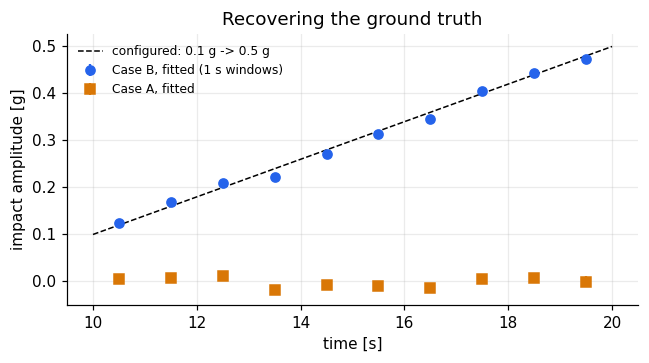

In [11]:
# Per-window impact amplitude, fitted by least squares (shaft lines removed), against the configured law
def window_amp(x, win=1.0):
    R, _ = train_regressors(len(x)); lines = np.column_stack([f(2*np.pi*fr*t) for fr in (30, 60, 90) for f in (np.sin, np.cos)])
    out = []
    for s in np.arange(10, 20, win):
        m = (t >= s) & (t < s + win); A = np.column_stack([lines[m], R[m, 0]]); c, *_ = np.linalg.lstsq(A, x[m], rcond=None)
        r = x[m] - A @ c; se = np.sqrt(np.linalg.inv(A.T @ A)[-1, -1] * r.var(ddof=A.shape[1])); out.append((s + win / 2, c[-1], se))
    return pd.DataFrame(out, columns=["t", "a", "se"])
wa = window_amp(X["Case B (physics)"]); wa_A = window_amp(X["Case A (naive)"])
fig, ax = plt.subplots(figsize=(6, 3.4)); tt_ = np.linspace(10, 20, 50)
ax.plot(tt_, 0.1 + 0.04 * (tt_ - 10), "k--", lw=1, label="configured: 0.1 g -> 0.5 g")
ax.errorbar(wa.t, wa.a, 2 * wa.se, fmt="o", color=COLORS["Case B (physics)"], label="Case B, fitted (1 s windows)")
ax.errorbar(wa_A.t, wa_A.a, 2 * wa_A.se, fmt="s", color=COLORS["Case A (naive)"], label="Case A, fitted")
ax.set(xlabel="time [s]", ylabel="impact amplitude [g]", title="Recovering the ground truth"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "06_amplitude_recovery.png", bbox_inches="tight"); plt.show()

In [12]:
summary = dict(rms_growth_18_20=rms_growth, detect=detect.to_dict("records"), env_lines=env_lines,
               fit={k: dict(zip(["a0", "a1", "se0", "se1"], map(float, fit_fault_train(X[k], t)))) for k in names})
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=1, default=float)); detect

,indicator,threshold (healthy mean + 4 sd),Case A (naive),Case B (physics),false alarms in healthy 0-10 s
0,RMS (raw),0.3973,3.25 s,3.00 s,0
1,RMS 400-800 Hz,0.0150,1.50 s,0.75 s,0
2,Kurtosis 400-800 Hz,3.4772,no alarm,no alarm,0
3,Crest factor 400-800 Hz,4.7115,no alarm,no alarm,0
4,Envelope line at 162 Hz,3.9173,no alarm,1.00 s,0


## 4. Monte Carlo: 30 seeds per case
The configurations `case_a.json`, `case_b.json` and `case_c.json` were run with seeds 1001 to 1030 through the tseriz API (90 series; seed 4242 reproduced the UI series for A and B to float32 precision). **Case C** is Case B with the amplitude ramp removed: 0.1 g impacts at 162 Hz from 10 s, constant (no growth), everything else identical, so the fault is as strong as Case B at its very first impact. Everything above is one noise realisation; here the same analysis is repeated on all 90.

In [13]:
import glob
MC = Path(os.environ.get("TSERIZ_MC", DATA / "mc")); cache = RESULTS / "mc_features.csv"
if cache.exists():
    mcf = pd.read_csv(cache)
else:
    parts = []
    for f in sorted(glob.glob(str(MC / "case_*_seed*.csv"))):
        case = "A" if "case_a" in f else ("C" if "case_c" in f else "B"); seed = int(Path(f).stem.split("seed")[1])
        x = pd.read_csv(f, usecols=["vibration"])["vibration"].to_numpy(float); tt = np.arange(len(x)) / FS
        d = window_features(x, tt, win=1.0, step=0.25); d["t_end"] = d.t + 0.5; d["case"] = case; d["seed"] = seed; parts.append(d)
    mcf = pd.concat(parts, ignore_index=True); mcf.to_csv(cache, index=False)
print(mcf.groupby("case").seed.nunique().to_dict(), "series")

{'A': 30, 'B': 30, 'C': 30} series


In [14]:
def delays(df, calib_end=ONSET, test=None):
    rows = []
    for (case, seed), g in df.groupby(["case", "seed"]):
        g = g.sort_values("t_end"); h = g[g.t_end <= calib_end]
        for f_ in feats:
            thr = h[f_].mean() + 4 * h[f_].std()
            if test is None:
                at = alarm_time(g.t_end.to_numpy(), g[f_].to_numpy(), thr, k=3); rows.append(dict(case=case, seed=seed, feat=f_, delay=at - ONSET if at == at else np.nan))
            else:
                s_ = g[(g.t_end > test[0]) & (g.t_end <= test[1])]; at = alarm_time(s_.t_end.to_numpy(), s_[f_].to_numpy(), thr, k=3); rows.append(dict(case=case, seed=seed, feat=f_, fa=int(at == at)))
    return pd.DataFrame(rows)
D = delays(mcf); tab = []
for f_, lab in feats.items():
    r = {"indicator": lab}
    for c in "ABC":
        s_ = D[(D.feat == f_) & (D.case == c)].delay; n = int(s_.notna().sum()); r[f"Case {c} detected"] = f"{n}/30"
        r[f"Case {c} median [s]"] = round(s_.median(), 2) if n else None
        r[f"Case {c} p10-p90 [s]"] = f"{s_.quantile(.1):.2f}-{s_.quantile(.9):.2f}" if n >= 10 else "-"
    tab.append(r)
mc_table = pd.DataFrame(tab); mc_table

,indicator,Case A detected,Case A median [s],Case A p10-p90 [s],Case B detected,Case B median [s],Case B p10-p90 [s],Case C detected,Case C median [s],Case C p10-p90 [s]
0,RMS (raw),30/30,4.50,3.50-5.75,30/30,3.75,2.50-5.00,9/30,6.00,-
1,RMS 400-800 Hz,30/30,1.50,1.25-1.75,30/30,0.75,0.75-0.75,30/30,0.75,0.75-0.75
2,Kurtosis 400-800 Hz,2/30,5.88,-,0/30,NaN,-,0/30,NaN,-
3,Crest factor 400-800 Hz,1/30,5.50,-,0/30,NaN,-,0/30,NaN,-
4,Envelope line at 162 Hz,0/30,NaN,-,30/30,0.75,0.75-1.00,30/30,0.88,0.75-1.00


In [15]:
# False alarms on healthy data held out from the calibration: threshold from 0-6 s, alarm rule applied to 6-10 s
FA = delays(mcf, calib_end=6.0, test=(6.0, 10.0)).groupby("feat").fa.sum().rename("false alarms in 90 series").to_frame(); FA.index = [feats[i] for i in FA.index]; FA

,false alarms in 90 series
RMS 400-800 Hz,3
Envelope line at 162 Hz,3
Crest factor 400-800 Hz,6
Kurtosis 400-800 Hz,0
RMS (raw),0


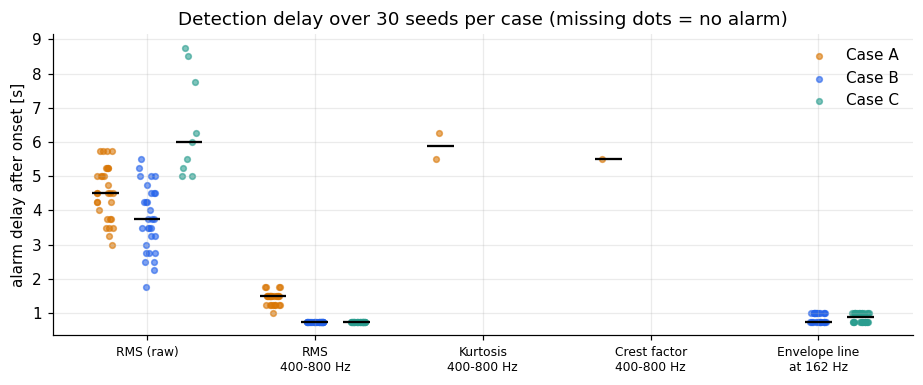

In [16]:
fig, ax = plt.subplots(figsize=(8.5, 3.6)); rng = np.random.default_rng(0); xs = np.arange(len(feats))
for off, c, col in ((-0.25, "A", COLORS["Case A (naive)"]), (0.0, "B", COLORS["Case B (physics)"]), (0.25, "C", "#2a9d8f")):
    for i, f_ in enumerate(feats):
        v = D[(D.feat == f_) & (D.case == c)].delay.dropna().to_numpy()
        ax.scatter(i + off + rng.uniform(-.05, .05, len(v)), v, s=14, color=col, alpha=.6, label=f"Case {c}" if i == 0 else None)
        if len(v): ax.hlines(np.median(v), i + off - .08, i + off + .08, color="k", lw=1.5)
ax.set_xticks(xs); ax.set_xticklabels([l.replace(" 400-800 Hz", "\n400-800 Hz").replace("Envelope line at 162 Hz", "Envelope line\nat 162 Hz") for l in feats.values()], fontsize=8)
ax.set(ylabel="alarm delay after onset [s]", title="Detection delay over 30 seeds per case (missing dots = no alarm)"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "07_mc_delays.png", bbox_inches="tight"); plt.show()

### Does a detector built on naive degradation catch the physical fault, including the weak one, and the other way round?
Logistic regression on the window features, healthy windows (label 0) against fully degraded windows (label 1, windows straddling the onset removed). Trained on seeds 1001-1015 of one case, tested on seeds 1016-1030 of the same or the other case.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
cd = mcf[(mcf.t_end <= ONSET) | (mcf.t >= ONSET + 0.5)].copy(); cd["y"] = (cd.t >= ONSET + 0.5).astype(int)
SETS = {"classic: RMS, band RMS, kurtosis, crest": ["rms", "band_rms", "kurt_band", "crest_band"], "classic + envelope line": ["rms", "band_rms", "kurt_band", "crest_band", "bpfi_line"], "overall RMS only": ["rms"]}
rows = []
for name, cols in SETS.items():
    for tc in "ABC":
        tr_ = cd[(cd.case == tc) & cd.seed.between(1001, 1015)]; m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr_[cols], tr_.y)
        for ec in "ABC":
            te_ = cd[(cd.case == ec) & cd.seed.between(1016, 1030)]; p = m.predict_proba(te_[cols])[:, 1]
            rows.append({"features": name, "trained on": tc, "tested on": ec, "AUC": round(roc_auc_score(te_.y, p), 3), "recall": round((p > .5)[te_.y == 1].mean(), 3), "false positives": round((p > .5)[te_.y == 0].mean(), 3)})
cross = pd.DataFrame(rows); cross

,features,trained on,tested on,AUC,recall,false positives
0,"classic: RMS, band RMS, kurtosis, crest",A,A,0.999,0.926,0.000
1,"classic: RMS, band RMS, kurtosis, crest",A,B,1.000,1.000,0.000
2,"classic: RMS, band RMS, kurtosis, crest",A,C,1.000,1.000,0.000
3,"classic: RMS, band RMS, kurtosis, crest",B,A,0.668,0.027,0.000
4,"classic: RMS, band RMS, kurtosis, crest",B,B,1.000,1.000,0.000
5,"classic: RMS, band RMS, kurtosis, crest",B,C,1.000,0.903,0.000
6,"classic: RMS, band RMS, kurtosis, crest",C,A,0.916,0.600,0.000
7,"classic: RMS, band RMS, kurtosis, crest",C,B,1.000,1.000,0.000
8,"classic: RMS, band RMS, kurtosis, crest",C,C,1.000,1.000,0.000
9,classic + envelope line,A,A,0.999,0.926,0.000


### Case C: what the weak fault does to each indicator
Median over 30 seeds of each indicator through time, relative to the healthy level (units of the healthy standard deviation), and the separation of C from A at the end of the record.

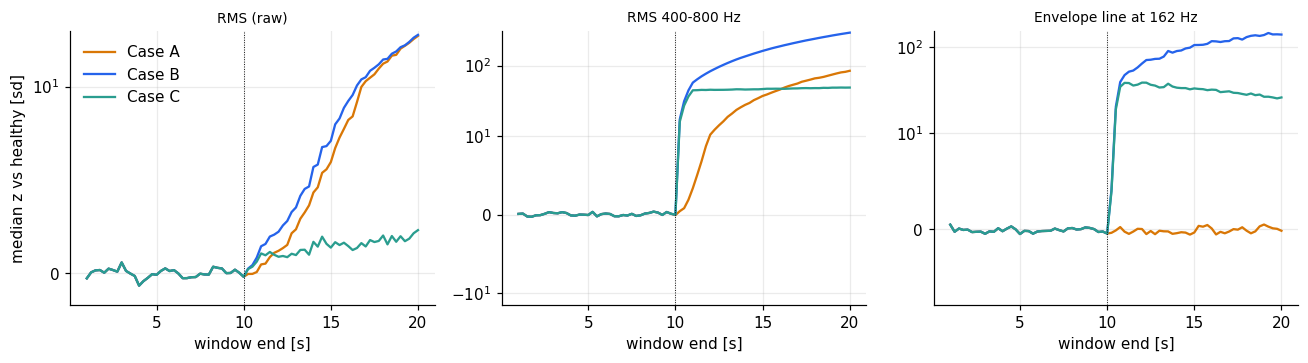

                           RMS  band RMS  envelope line
median z after onset [sd]                              
A                          7.1      41.2           -0.2
B                          8.3     174.7          106.7
C                          1.5      46.8           32.1
AUC A vs C, windows ending >= 19 s: {'rms': 0.0, 'band_rms': 0.0, 'kurt_band': 0.0, 'crest_band': 0.02, 'bpfi_line': 1.0}


In [18]:
cols_ = {"A": COLORS["Case A (naive)"], "B": COLORS["Case B (physics)"], "C": "#2a9d8f"}
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for a_, f_ in zip(ax, ["rms", "band_rms", "bpfi_line"]):
    for c in "ABC":
        g_ = mcf[mcf.case == c]; h_ = g_[g_.t_end <= ONSET][f_]; z_ = (g_[f_] - h_.mean()) / h_.std()
        m_ = z_.groupby(g_.t_end).median(); a_.plot(m_.index, m_.values, color=cols_[c], label=f"Case {c}")
    a_.axvline(ONSET, color="k", lw=.6, ls=":"); a_.set_yscale("symlog", linthresh=10); a_.set_title(feats[f_], fontsize=9); a_.set_xlabel("window end [s]")
ax[0].set_ylabel("median z vs healthy [sd]"); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "08_case_c_indicators.png", bbox_inches="tight"); plt.show()
post = mcf[mcf.t >= ONSET + 0.5]; late_ = mcf[mcf.t_end >= 19]
zt = {}
for c in "ABC":
    g_ = mcf[mcf.case == c]; h_ = g_[g_.t_end <= ONSET]
    zt[c] = {f_: round(((g_[g_.t >= ONSET + 0.5][f_] - h_[f_].mean()) / h_[f_].std()).median(), 1) for f_ in ["rms", "band_rms", "bpfi_line"]}
z_table = pd.DataFrame(zt).T; z_table.columns = ["RMS", "band RMS", "envelope line"]; z_table.index.name = "median z after onset [sd]"
sep = {f_: round(roc_auc_score((late_.case == "C").astype(int)[late_.case.isin(["A", "C"])], late_[late_.case.isin(["A", "C"])][f_]), 3) for f_ in feats}
print(z_table.to_string()); print("AUC A vs C, windows ending >= 19 s:", sep)

In [19]:
summary.update(mc_table=mc_table.to_dict("records"), mc_false_alarms=FA.reset_index().to_dict("records"), cross=cross.to_dict("records"), case_c_z=z_table.reset_index().to_dict("records"), auc_A_vs_C=sep)
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=1, default=float))

8805